In [32]:
# Import libraries needed
import numpy as np
import pandas as pd
# For graph plot
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

In [33]:
# Import data and settings
df = pd.read_csv("data.csv")

mete_col = ["Diurnal temperature range (°C)", "Mean temperature (°C)", "Mean humidity (%)", "Solar radiation (MJ/m²)", "Air pressure (hPa)", "Dew point temperature (°C)", "Wind speed (km/h)", "Mean UV"]
flu_col = ["H1", "H3", "B", "AandB"]


In [34]:
# Quick overview of the data
df.head()

,Year,Week,From,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),Air pressure (hPa),Dew point temperature (°C),Wind speed (km/h),Mean UV,H1,H3,B,AandB
0,2002,36,2002-09-01,14.3,28.15,76.5,19.66,1008.20,23.20,7.35,4.0,1,12,3.0,19
1,2002,37,2002-09-08,13.6,26.70,85.0,9.35,1006.30,23.80,10.50,3.0,0,6,4.0,15
2,2002,38,2002-09-15,11.2,26.40,83.0,16.75,1011.35,23.20,13.45,4.0,0,4,4.0,13
3,2002,39,2002-09-22,10.0,25.90,85.0,10.93,1012.90,23.25,13.25,3.0,0,2,6.0,10
4,2002,40,2002-09-29,10.6,25.95,82.0,11.56,1012.80,22.40,10.05,3.0,0,6,2.0,8


In [35]:
# Infromation of the DataFrmae
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1253 entries, 0 to 1252
Data columns (total 15 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Year                            1253 non-null   int64  
 1   Week                            1253 non-null   int64  
 2   From                            1253 non-null   object 
 3   Diurnal temperature range (°C)  1253 non-null   float64
 4   Mean temperature (°C)           1253 non-null   float64
 5   Mean humidity (%)               1253 non-null   float64
 6   Solar radiation (MJ/m²)         1253 non-null   float64
 7   Air pressure (hPa)              1253 non-null   float64
 8   Dew point temperature (°C)      1253 non-null   float64
 9   Wind speed (km/h)               1253 non-null   float64
 10  Mean UV                         1253 non-null   float64
 11  H1                              1253 non-null   int64  
 12  H3                              12

In [36]:
# Statistical information for the meteorological data
df[mete_col].describe()

,Diurnal temperature range (°C),Mean temperature (°C),Mean humidity (%),Solar radiation (MJ/m²),Air pressure (hPa),Dew point temperature (°C),Wind speed (km/h),Mean UV
count,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000
mean,14.864006,23.383599,78.736233,13.996983,1012.860774,19.225339,10.074062,2.891700
std,3.539967,5.005770,8.494599,5.270534,6.067874,5.963239,1.811932,1.256406
min,3.900000,8.900000,43.000000,2.020000,996.750000,-0.100000,5.550000,0.400000
25%,12.200000,19.100000,74.500000,9.930000,1008.000000,14.900000,8.800000,2.000000
50%,14.000000,24.400000,80.000000,14.240000,1012.800000,20.500000,10.000000,3.000000
75%,17.000000,28.000000,85.000000,17.680000,1017.650000,24.800000,11.200000,4.000000
max,27.700000,31.700000,94.000000,26.460000,1027.700000,26.800000,17.800000,7.000000


In [37]:
# Statistical information for the influenza data
df[flu_col].describe()

,H1,H3,B,AandB
count,1253.000000,1253.000000,1252.000000,1253.000000
mean,69.613727,115.727055,44.593450,261.437350
std,189.083854,233.728958,131.615377,439.621172
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,5.000000,3.000000,27.000000
50%,4.000000,28.000000,12.500000,103.000000
75%,47.000000,125.000000,41.000000,305.000000
max,1999.000000,2560.000000,1978.000000,4679.000000


Note that the table above shows a high difference between the mean and standard deviation. 
For all influenza types, the lower quartile (25%) is 0, which means that the data is highly zero inflated.

In [ ]:
# Check missing values in each columns
print(f"Number of NA values in each rows: \n{df.isna().sum()}")

Number of NA values in each rows: 
Year                              0
Week                              0
From                              0
Diurnal temperature range (°C)    0
Mean temperature (°C)             0
Mean humidity (%)                 0
Solar radiation (MJ/m²)           0
Air pressure (hPa)                0
Dew point temperature (°C)        0
Wind speed (km/h)                 0
Mean UV                           0
H1                                0
H3                                0
B                                 1
AandB                             0
dtype: int64


In [40]:
# Check how many 0 exists in the target variables
(df[flu_col]==0).sum()

H1       472
H3       133
B        137
AandB     76
dtype: int64

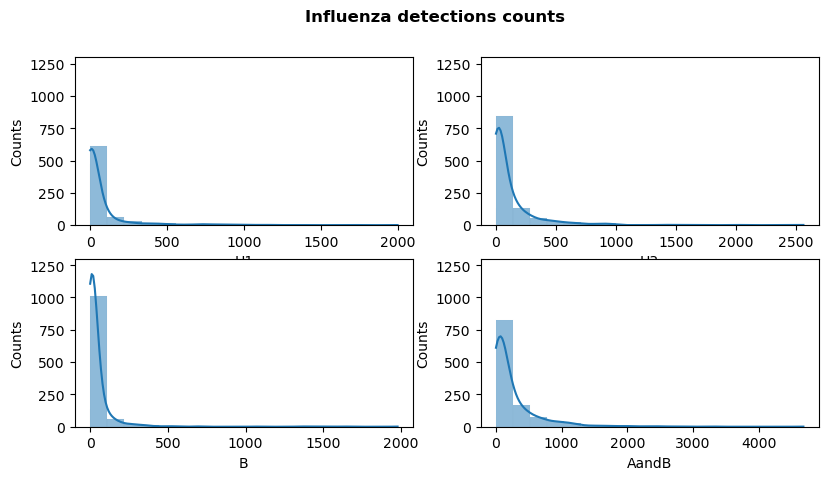

In [41]:
# Visualize the ratio of counts
fig, axes = plt.subplots(2, 2, figsize=(6.4*1.5, 4.8))

for i, col in enumerate(flu_col):
    remaining = np.linspace(1, df[col].max(), 19)
    custom_bins = np.insert(remaining, 0, 0)
    
    sns.histplot(x=col, data=df, ax=axes[i//2, i%2], kde=True, bins=custom_bins)
    axes[i//2, i%2].set_xlabel(col)
    axes[i//2, i%2].set_ylabel("Counts")
    axes[i//2, i%2].set_ylim(0, 1300)
    
plt.suptitle("Influenza detections counts", fontweight="bold")
plt.show()

We can see that the influenza data are inflated by zero

Find the correlation between the meterological data and influenza count, then visualize it using a heatmap

,H1,H3,B,AandB
Diurnal temperature range (°C),-0.021623,-0.112394,0.042635,-0.046062
Mean temperature (°C),0.005841,0.098653,-0.122834,-0.026245
Mean humidity (%),0.106987,0.128419,0.128242,0.161329
Solar radiation (MJ/m²),-0.032933,-0.001178,-0.108846,-0.074390
Air pressure (hPa),-0.011485,-0.122832,0.041290,-0.039052
Dew point temperature (°C),0.051058,0.125961,-0.067376,0.034729
Wind speed (km/h),-0.081967,-0.085351,-0.020075,-0.050803
Mean UV,-0.066776,0.016252,-0.105686,-0.068360


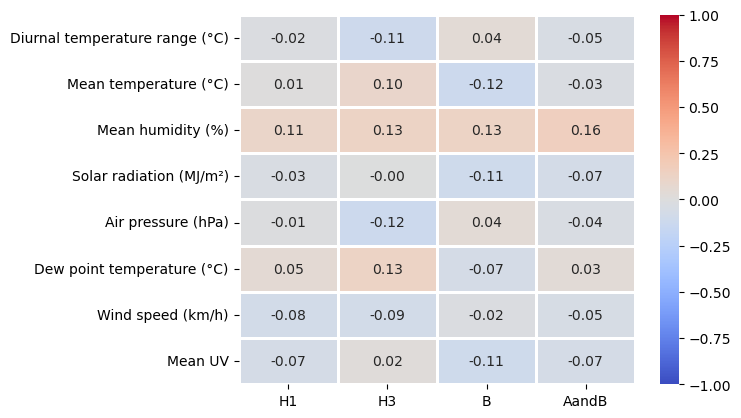

In [42]:
# correlation between meteorlogical factors and influenza detections
corr_df = df.drop(["Year", "Week", "From"], axis=1).corr(method="spearman")
corr_df = corr_df.loc[mete_col, flu_col]
display(corr_df)

sns.heatmap(corr_df, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", linewidth=1)
plt.show()

We use scatterplot to identify the realtionship between the meterological data and influenza case counts for different types of influenza. 
The x-axis are the meterological data, while the y-axis represents different type of influenza
From the figure below, we can see that all relationships are non-linear and is ... 

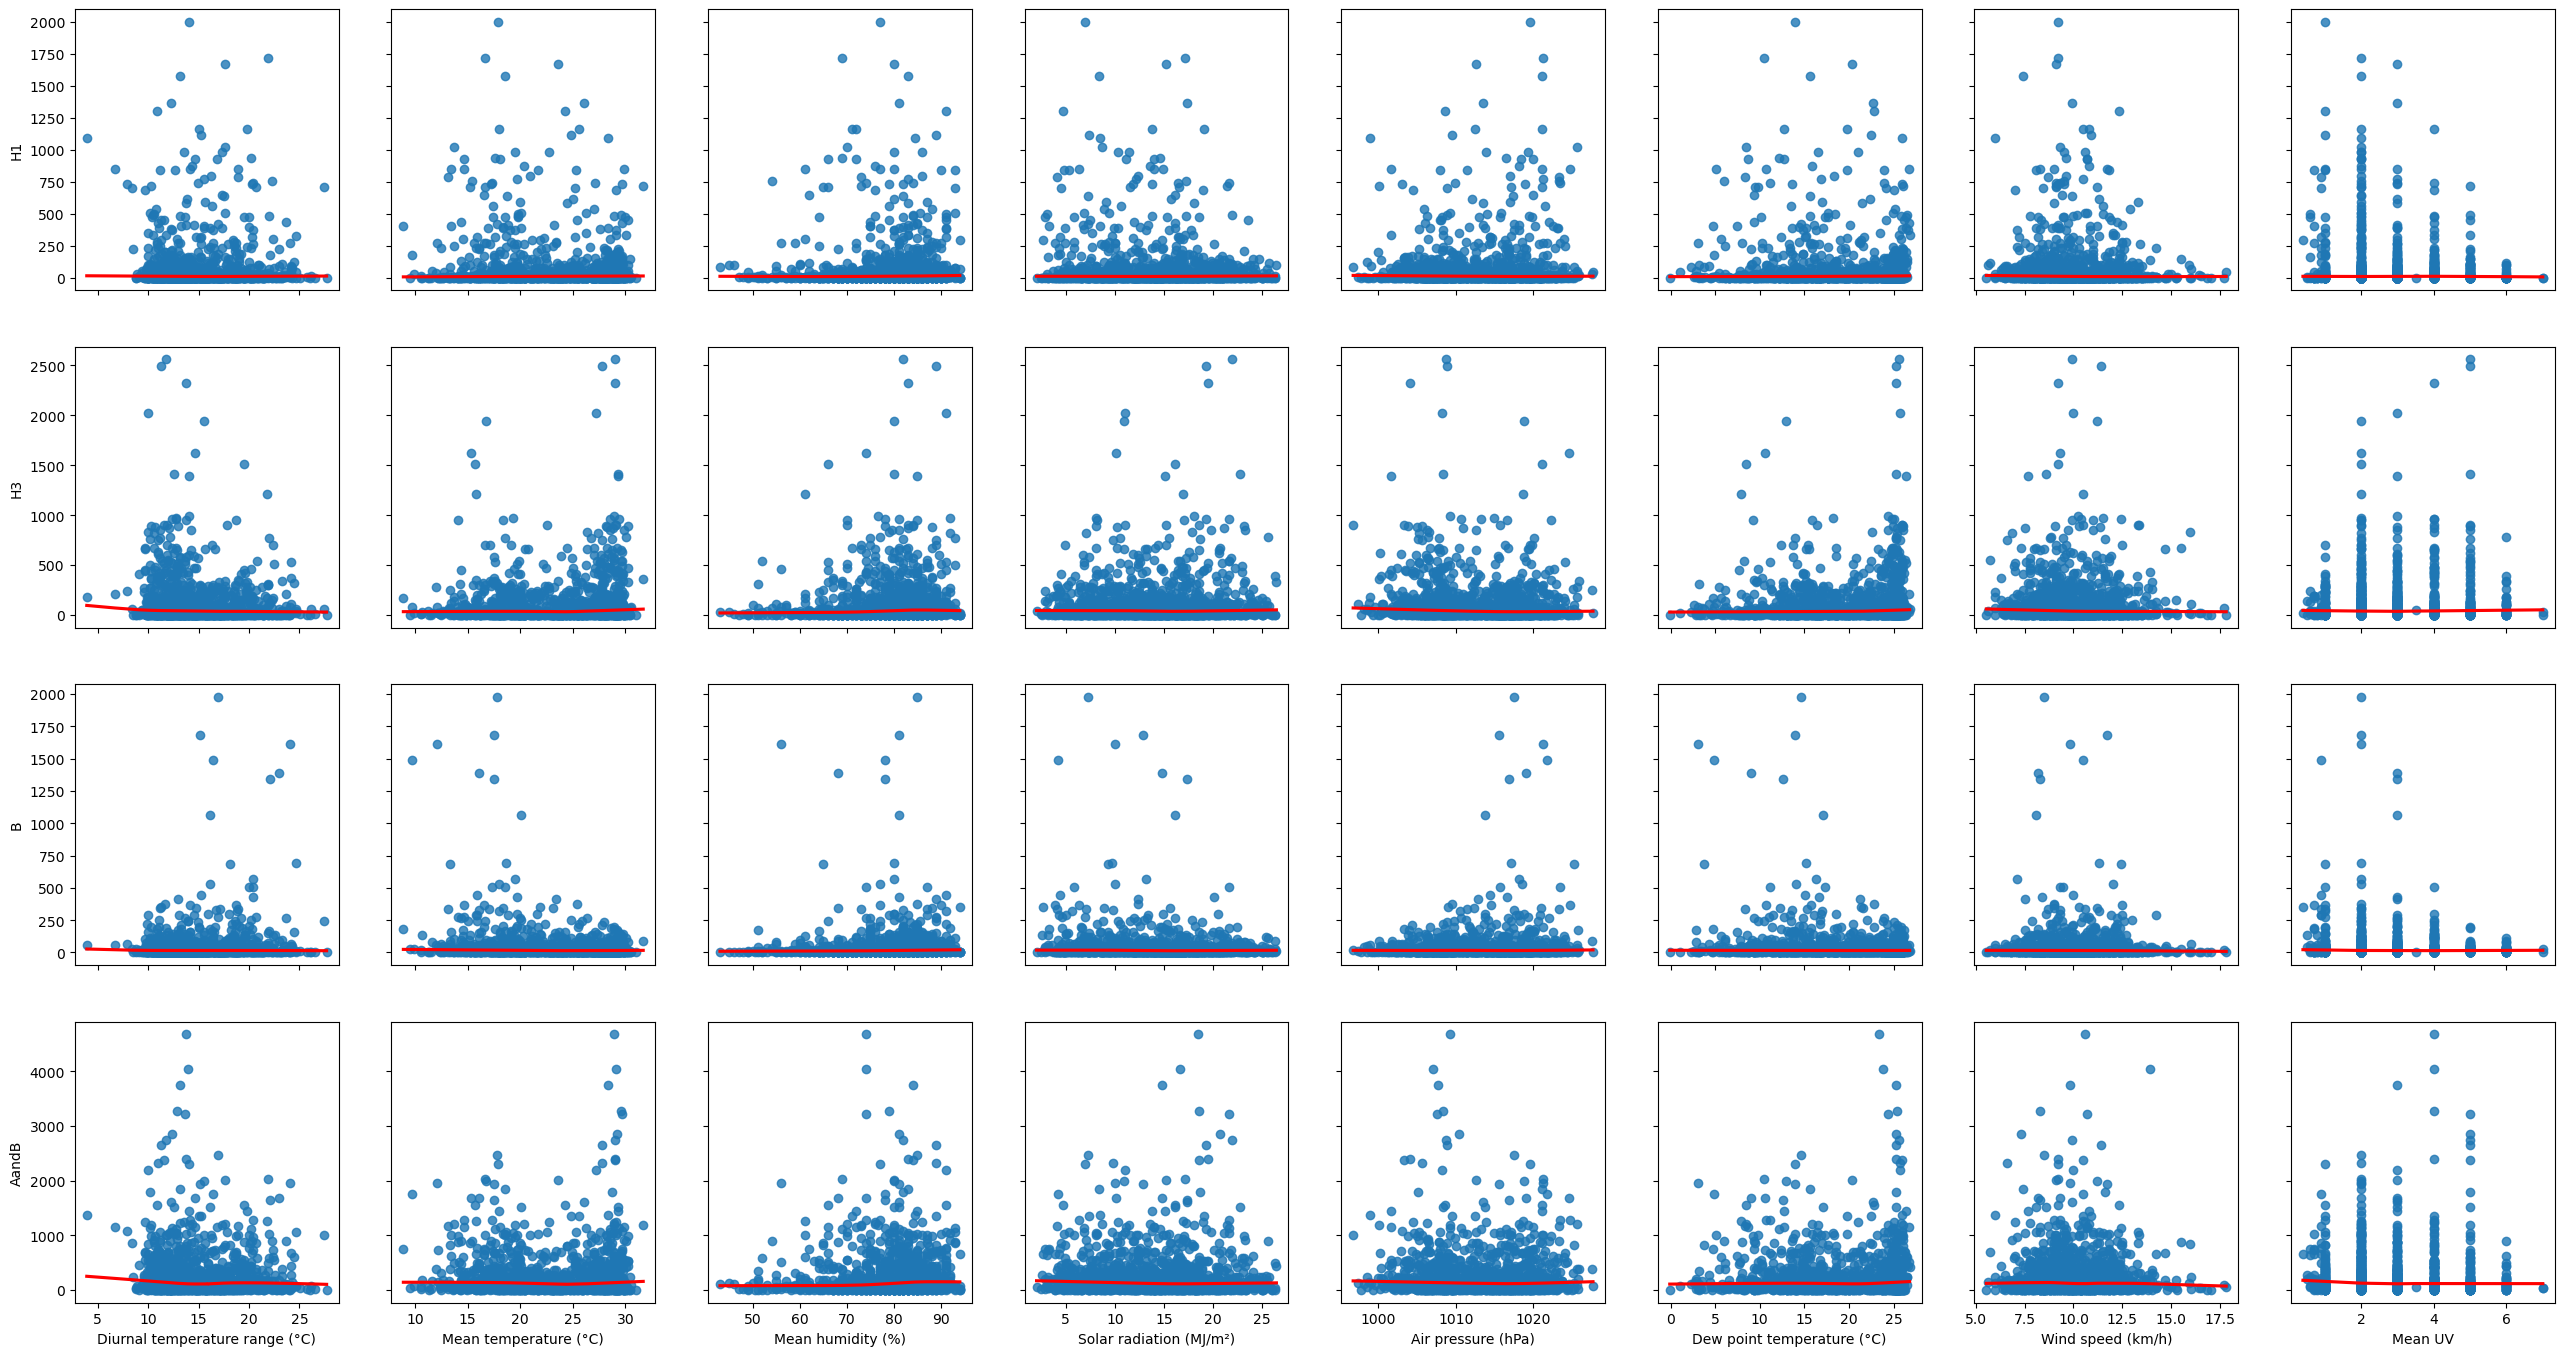

In [43]:
fig, axes = plt.subplots(4, 8, figsize=(6.4*5, 4.8*3.5))

for i, flu in enumerate(flu_col):
    for j, mete in enumerate(mete_col):
        sns.regplot(x=mete, y=flu, data=df, ax=axes[i, j], lowess=True, line_kws={"color": "red"})
        axes[i, j].set_xlabel(mete)
        axes[i, j].set_ylabel(flu)
        axes[i, j].label_outer()
        
plt.show()   


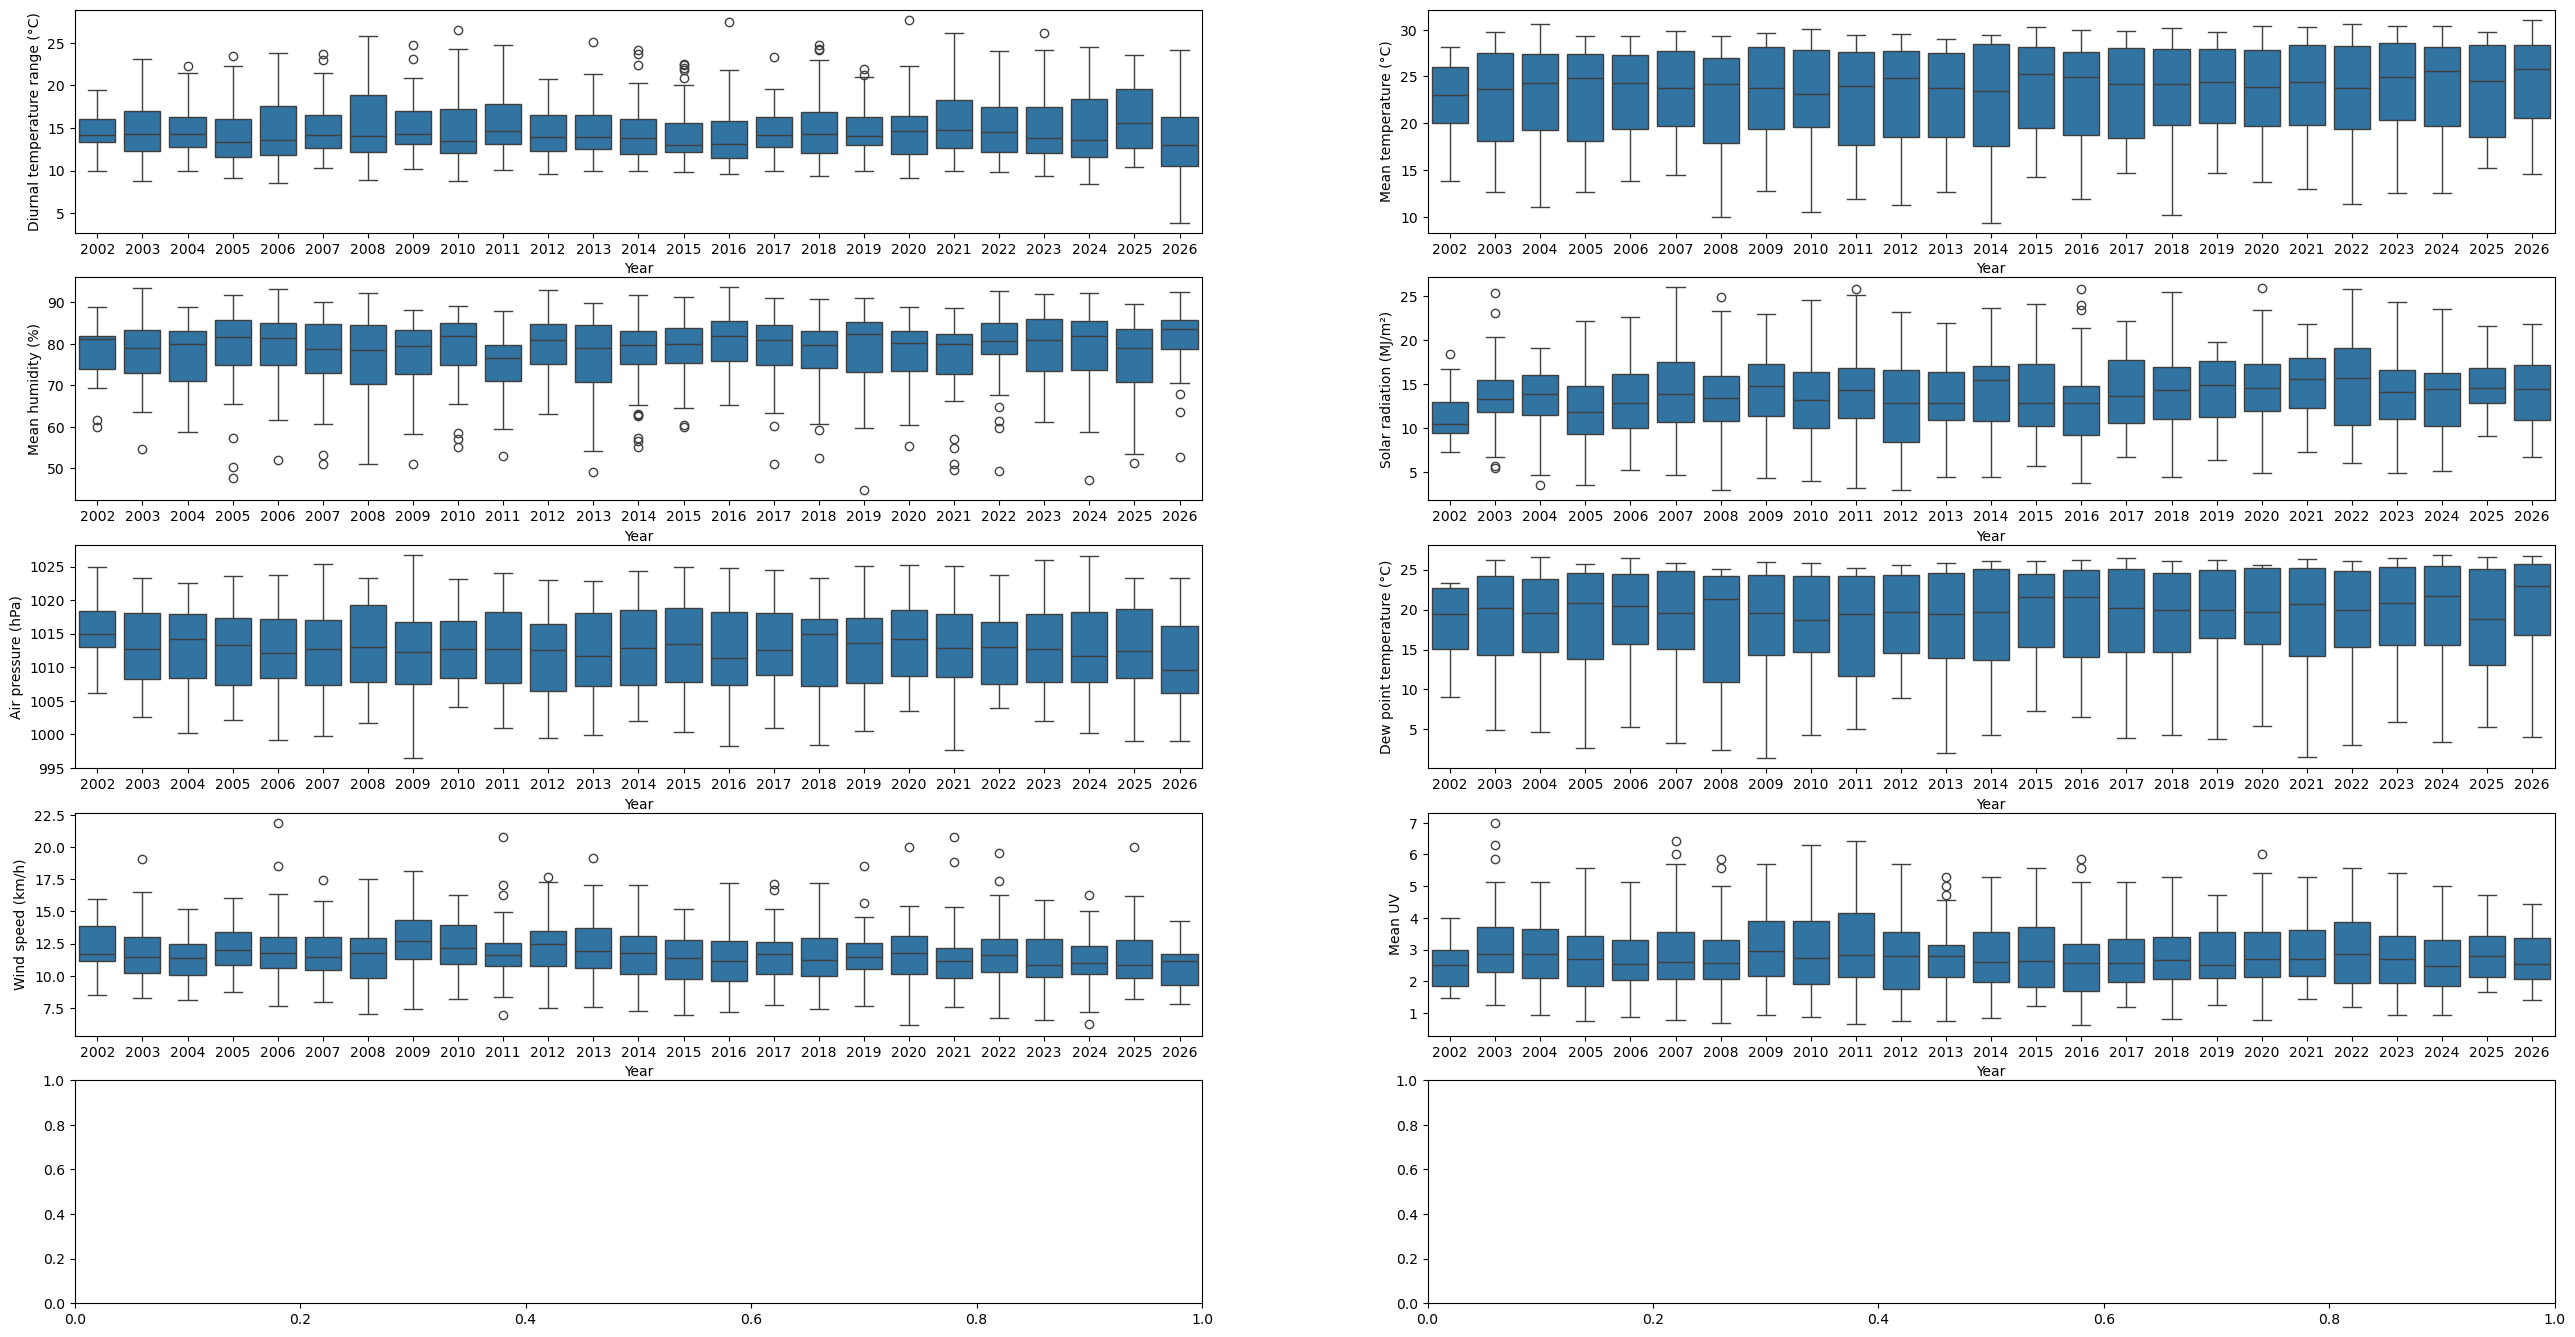

In [31]:
fig, axes = plt.subplots(5, 2, figsize=(6.4*5, 4.8*3.5))

for i, col in enumerate(mete_col):
    sns.boxplot(df[["Year", col]], x="Year", y=col, ax=axes[i//2, i%2])
    axes[i//2, i%2].set_xlabel("Year")
    axes[i//2, i%2].set_ylabel(col)

plt.show()

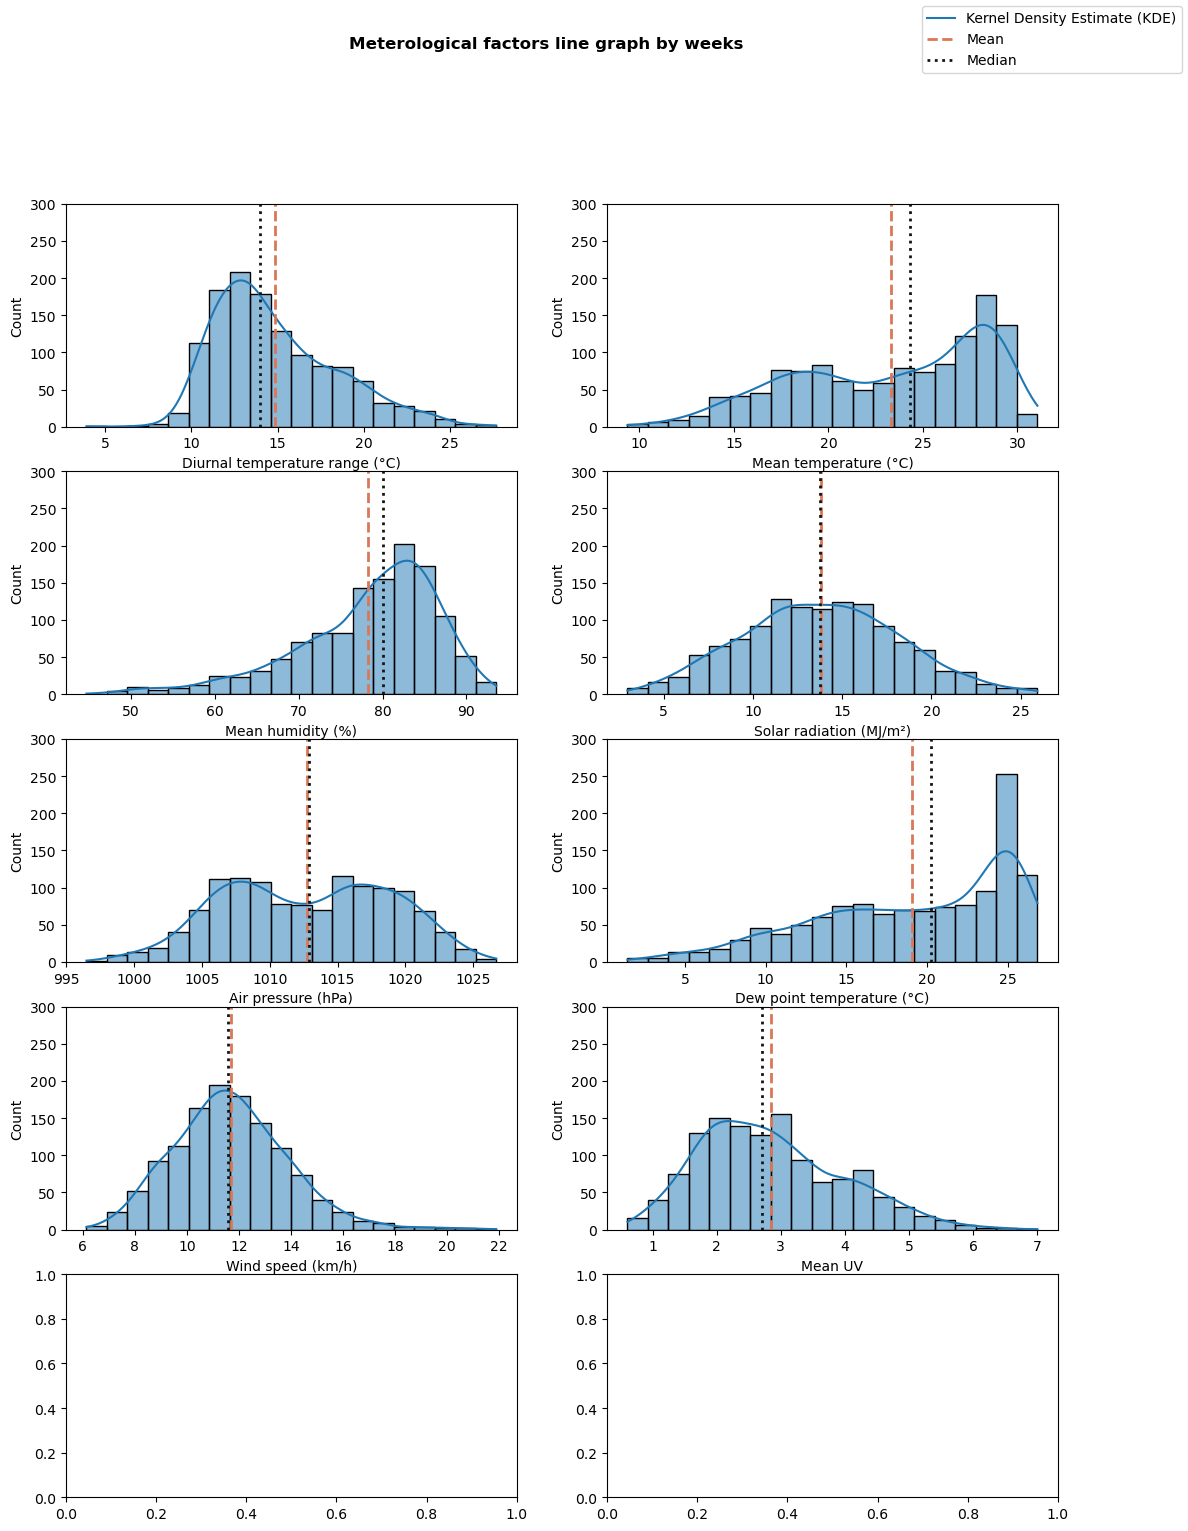

In [33]:
fig, axes = plt.subplots(5, 2, figsize=(6.4*2, 4.8*3.5))

for i, col in enumerate(mete_col):
    #sns.histplot(data=df, x=col, bins=20, ax=axes[i//2, i%2], kde=True, hue="Year")
    sns.histplot(data=df, x=col, bins=20, ax=axes[i//2, i%2], kde=True)
    axes[i//2, i%2].axvline(df[col].mean(), color="#d97757", linestyle="--", linewidth=2, label="Mean")
    axes[i//2, i%2].axvline(df[col].median(), color="#141413", linestyle=":", linewidth=2, label="Median")
    axes[i//2, i%2].set_xlabel(col)
    axes[i//2, i%2].set_ylabel("Count")
    axes[i//2, i%2].set_ylim(0, 300)
    
plt.suptitle("Meterological factors line graph by weeks", fontweight="bold")
fig.legend(["Kernel Density Estimate (KDE)", "Mean", "Median"])
plt.show()
    

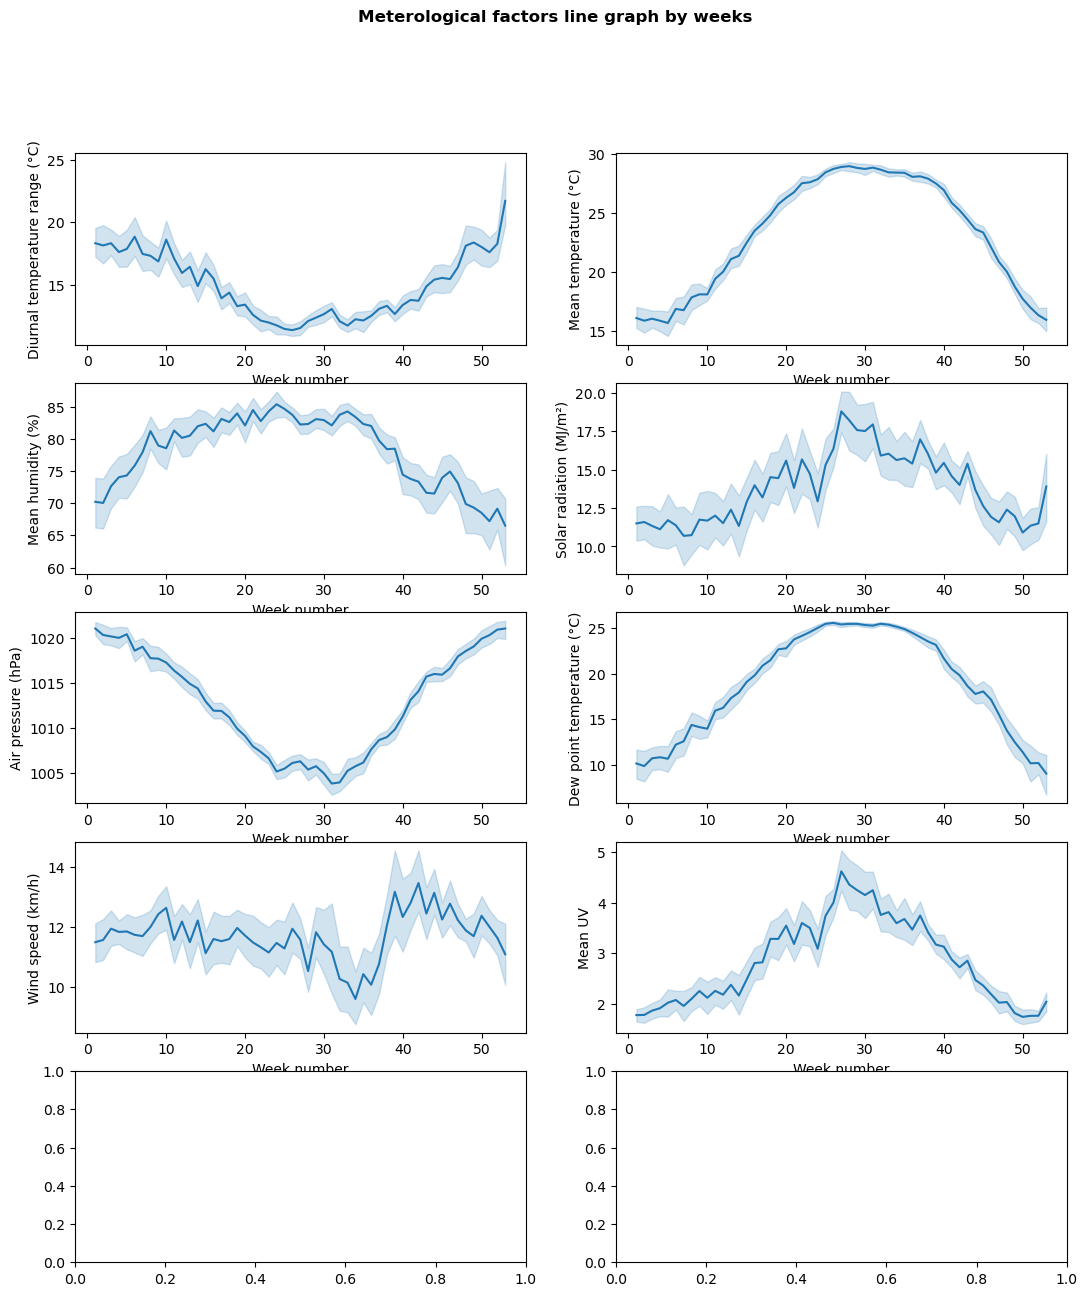

In [34]:
# remark: cannot simply take mean
fig, axes = plt.subplots(5, 2, figsize=(6.4*2, 4.8*3))

for i, col in enumerate(mete_col):
    sns.lineplot(x="Week", y=col, data=df, ax=axes[i//2, i%2])
    axes[i//2, i%2].set_xlabel("Week number")
    axes[i//2, i%2].set_ylabel(col)
    
plt.suptitle("Meterological factors line graph by weeks", fontweight="bold")
plt.show()
    

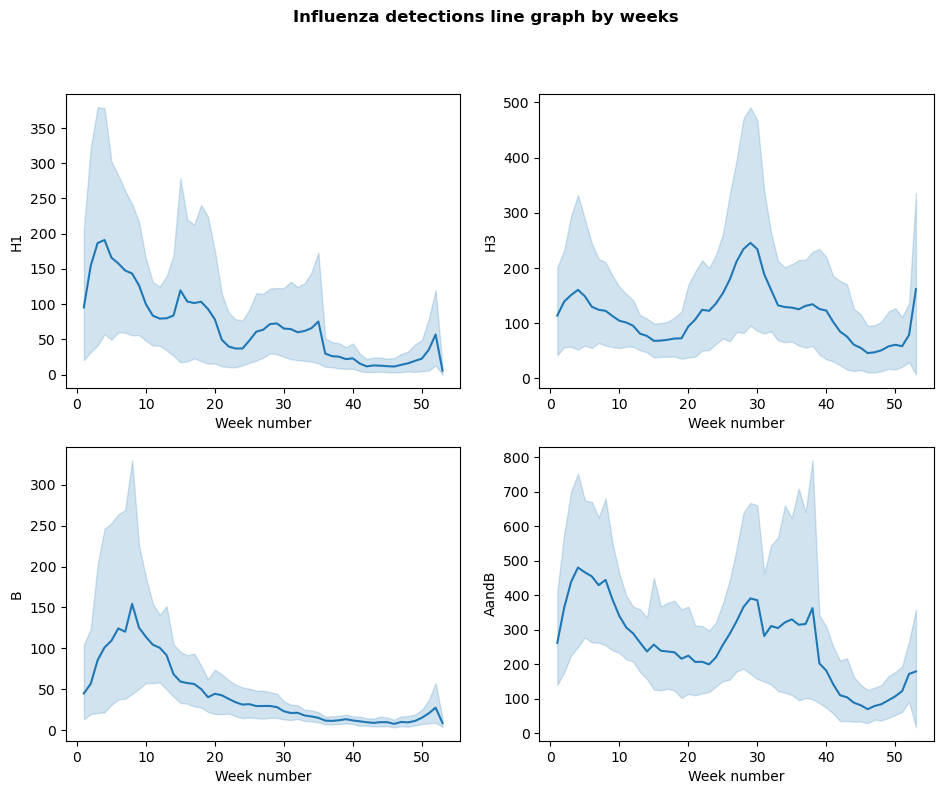

In [36]:
fig, axes = plt.subplots(2, 2, figsize=(6.4*1.75, 4.8*1.75))

for i, col in enumerate(flu_col):
    sns.lineplot(x="Week", y=col, data=df, ax=axes[i//2, i%2])
    axes[i//2, i%2].set_xlabel("Week number")
    axes[i//2, i%2].set_ylabel(col)
    
plt.suptitle("Influenza detections line graph by weeks", fontweight="bold")
plt.show()

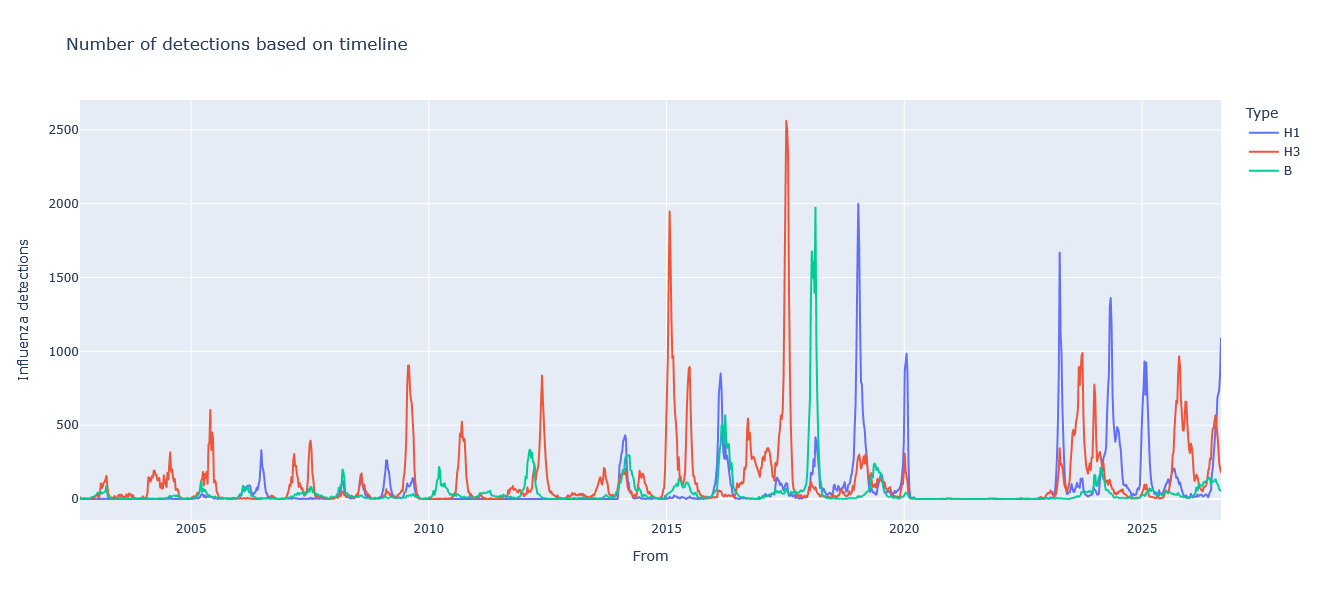

In [38]:
df_long = df.melt(
    id_vars=["From"],
    value_vars=["H1", "H3", "B"],
    var_name="Type",  
    value_name="Influenza detections",  
)

fig = px.line(df_long, "From", "Influenza detections", color="Type",
              title="Number of detections based on timeline", 
              width=1500, height=600
             )
"""
for year in sorted(df["Year"].unique()):
    start = pd.Timestamp(int(year), 6, 1)
    end = pd.Timestamp(int(year), 8, 31)
    fig.add_vrect(start, end, line_width=0, fillcolor="red", opacity=0.3)
    
    start = pd.Timestamp(int(year), 1, 1)
    end = pd.Timestamp(int(year), 2, 28)
    fig.add_vrect(start, end, line_width=0, fillcolor="blue", opacity=0.3)

    start = pd.Timestamp(int(year), 12, 1)
    end = pd.Timestamp(int(year), 12, 31)

    fig.add_vrect(start, end, line_width=0, fillcolor="blue", opacity=0.3)

fig.add_trace(
    go.Scatter(
        x=[None], y=[None],
        mode="markers",
        marker=dict(size=12, symbol="square", color="rgba(255, 0, 0, 0.3)"),
        name="Winter", 
        showlegend=True,
    )
)
fig.add_trace(
    go.Scatter(
        x=[None], y=[None],
        mode="markers",
        marker=dict(size=12, symbol="square", color="rgba(0, 0, 255, 0.3)"),
        name="Summer", 
        showlegend=True,
    )
)
"""

fig.show()